## Wstęp do Uczenia Maszynowego

#### Laboratorium 01



### Zakres laboratorium

- organizacja przedmiotu i podstawy pracy w Pythonie
- eksploracyjna analiza danych
- drzewa regresyjne i predykcja
- błąd średniokwadratowy (MSE)


### 0\. Sprawy organizacyjne

Kontakt: MS Teams

Lub mailowo: anna.kozak@pw.edu.pl, katarzyna.woznica@pw.edu.pl, krzyzinskimateusz23@gmail.com

Pracujemy z językiem `Python`.

Pracujemy z repozytorium GitHub: [https://github.com/kozaka93/2026Z-MachineLearning](https://github.com/kozaka93/2026Z-MachineLearning)

Na repozytorium będą się pojawiały pliki `.ipynb` z materiałami na zajęcia.

Rozwiązania kolejnych etapów projektu przesyłamy poprzez *Zadanie* w MS Teams w wyznaczonym terminie.


*Zasady zaliczenia (suma 140p):*

- Zajęcia laboratoryjne (80p):
  - projekt I (12p + 12p + 28p)
  - projekt II (16p)
  - niezapowiedziane wejściówki (12p = 3 x 4p)

- Egzamin (60p)

> Warunkiem koniecznym do dopuszczenia do egzaminu końcowego jest pomyślne ukończenie zajęć laboratoryjnych, czyli uzyskanie powyżej **50% punktów** możliwych do zdobycia.

> Warunkiem koniecznym do uzyskania pozytywnej oceny z przedmiotu jest zdobycie ponad **50% punktów** możliwych do uzyskania z egzaminu pisemnego.

Ocena końcowa ustalana jest na podstawie sumy punktów uzyskanych z zajęć laboratoryjnych oraz egzaminu pisemnego, według poniższego przelicznika:

| Ocena |  3 | 3.5 | 4 | 4.5 | 5 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| Punkty   | (70, 84] | (84, 98] | (98, 112] | (112, 126] | (126, ∞) |

-----

### 1\. Czym będziemy się zajmować?

<img src="tematy.png" alt="drawing" width="800">

W uczeniu maszynowym pracujemy ze zbiorem danych $\mathbf{D}= (X, Y)$.

  - $X$ to **macierz cech** (zmiennych niezależnych) o wymiarze $n \times p$ ($n$ próbek, $p$ cech).
  - $Y$ to **wektor zmiennej docelowej** (etykieta, wynik, który chcemy przewidzieć) o wymiarze $n$.

#### Rodzaje Uczenia Maszynowego

1.  **Uczenie nadzorowane (Supervised Learning):** Jeżeli wartość $Y$ jest znana w zbiorze treningowym (czyli mamy dane wejściowe **i** poprawne odpowiedzi). Chcemy, aby model nauczył się mapowania $X \rightarrow Y$.
      * **Regresja (Regression):** Gdy zmienna $Y$ jest ciągła (np. zarobki, temperatura, cena domu, czyli $Y \in R$).
      * **Klasyfikacja (Classification):** Gdy zmienna $Y$ jest dyskretna (kategorie, klasy, np. tak/nie, kot/pies/mysz, czyli $Y \in \{0, 1, 2, ..\}$). Gdy $Y \in \{0,1\}$ mówimy o klasyfikacji binarnej.
2.  **Uczenie nienadzorowane (Unsupervised Learning):** Jeżeli nie znamy wartości $Y$ (brakuje nam etykiet). Celem jest znalezienie ukrytych wzorców i struktury w samych danych $X$ (np. grupowanie danych w skupienia).

-----

### 2\. Jak wygląda proces uczenia?

Proces uczenia maszynowego polega na stworzeniu **modelu** $\mathbf{M}$, który na podstawie danych wejściowych $X$ potrafi przewidzieć wartość docelową $\hat{Y}$.

**Model:** $\mathbf{M}: D \rightarrow \hat{Y}$

**Prognoza:** $\hat{Y} = M(X)$ .

Model jest "uczony" na danych $D$, aby jak najlepiej minimalizować błąd między przewidywanym $\hat{Y}$ a rzeczywistym $Y$.

-----

### 3\. Etapy uczenia maszynowego

#### 3.1 Pakiety i dane



In [1]:
# Import potrzebnych pakietów (bibliotek)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 'sklearn' (scikit-learn)  biblioteka do uczenia maszynowego w Pythonie.
# Z niej importujemy konkretne algorytmy, np. 'tree' (Drzewa Decyzyjne).
from sklearn import tree

# Będziemy też potrzebować funkcji do podziału danych
from sklearn.model_selection import train_test_split

# Metryka do oceny modelu (np. błąd średniokwadratowy)
from sklearn.metrics import mean_squared_error

> Zaleca się importowanie tylko konkretnych komponentów, między innymi dlatego, że:
- nasz skrypt będzie miał szybszy start
- oszczędamy pamięć RAM
- mamy czytelny kod
- mamy porządek w nazwach i brak konfliktów
- edytory (VS Code, PyCharm) szybciej i celniej będą podpowiadać składnię
- łatwiej wykryjemy "martwy" kod (nieużywany import będzie podświetlony)

Rozważmy zbiór danych zawierający informacje o zarobkach zawodników baseballu.

In [3]:
# Zbiory danych można wczytać przez link z GitHub, nie ma konieczności ich pobierania.
# index_col =[0] mówi, aby pierwszą kolumnę pliku CSV potraktować jako indeks wierszy.
Hitters = pd.read_csv("Hitters.csv", index_col =[0])

-----

#### 3.2 Przygotowanie danych (Pre-processing)

##### *Zadanie 1*

Przygotuj zbiór danych do zbudowania pierwszego modelu.

a) Utwórz zbiór *Hitters\_small* zawierający zmienne o nazwach *Years, Hits, Salary*.

b) Przyjrzyj się utworzonemu zbiorowi danych. Jaki jest wymiar danych, typy zmiennych, czy są braki danych? Jakie rozkłady mają zmienne?

c) Podziel zbiór danych na X = ['Years', 'Hits'] (cechy) i y = ['Salary'] (zmienna docelowa).

d) Podziel dane na zbiór treningowy i testowy (proporcja 50:50).

**Rozwiązanie Zadania 1**

In [6]:
# a) 
Hitters_small = Hitters[["Years", "Hits", "Salary"]]

<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Years   322 non-null    int64  
 1   Hits    322 non-null    int64  
 2   Salary  263 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 7.7 KB


array([[<Axes: title={'center': 'Years'}>,
        <Axes: title={'center': 'Hits'}>],
       [<Axes: title={'center': 'Salary'}>, <Axes: >]], dtype=object)

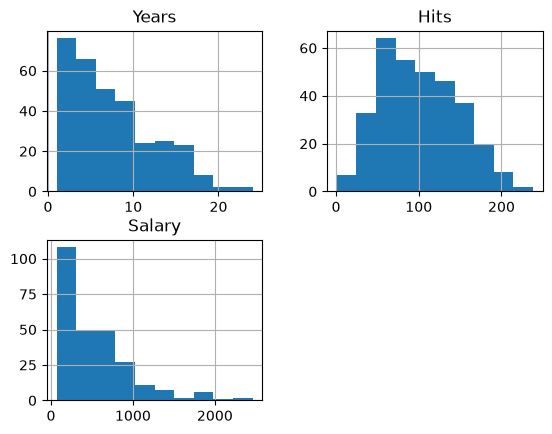

In [27]:
# b) 
Hitters_small.info()
Hitters_small.hist()

In [28]:
# c) 
Hitters_small.dropna(inplace=True)
X = Hitters_small[["Years", "Hits"]]
y = Hitters_small["Salary"]

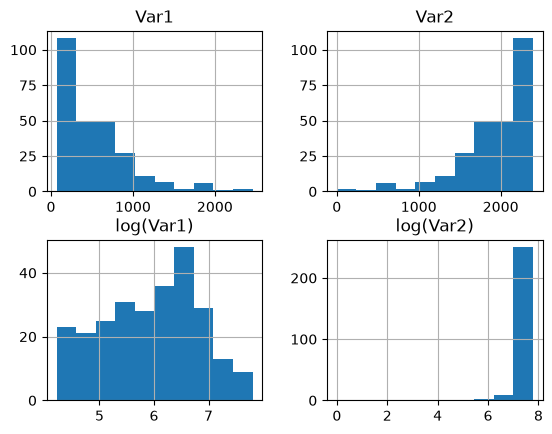

In [22]:
## Eksperyment - transformacja log zmiennych skośnych

experiment = pd.DataFrame({"Var1" : Hitters.Salary,
                           # stała większa od maksimum, żeby argument logarytmu był dodatni
                           "Var2": Hitters.Salary.max() + 1 - Hitters.Salary})

experiment["log(Var1)"] = np.log(experiment.Var1)
experiment["log(Var2)"] = np.log(experiment.Var2)

experiment.hist()
plt.show()

Text(0, 0.5, 'Years')

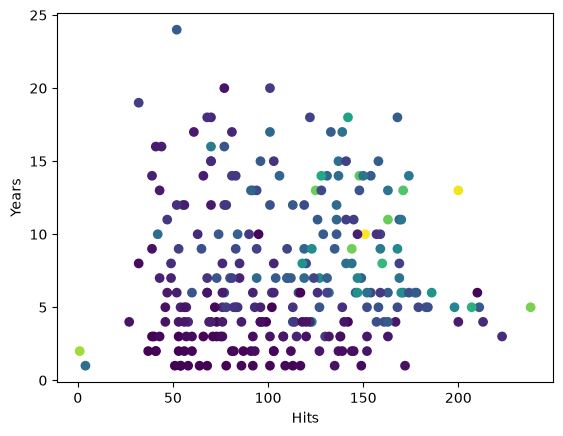

In [69]:
plt.scatter(Hitters_small["Hits"], Hitters_small["Years"], c=Hitters_small["Salary"])
plt.xlabel("Hits")
plt.ylabel("Years")

In [30]:
# d) 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=123)

#### 3.3 Podstawy drzew decyzyjnych 

#### *Jak się buduje drzewa dla zadania regresji?*
1. Dzielimy przestrzeń $X = (X_1, X_2, \dots, X_p)$ na $J$ regionów $R_1, R_2, \dots, R_J$.
2. Predykcja w $j$-tym regionie jest równa średniej wartości obserwacji $y$ ze zbioru treningowego znajdujących się w regionie $R_j$. 

In [32]:
# Tworzymy obiekt klasy DecisionTreeRegressor.
# Drzewo będzie miało domyślne parametry.
Tree = tree.DecisionTreeRegressor()

# Trening (uczenie) modelu: Używamy metody .fit(), aby nauczyć model na danych treningowych.
Tree.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree wi

Wizualizacja drzewa decyzyjnego

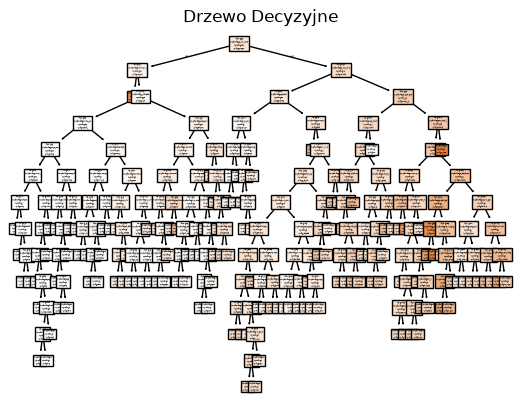

In [33]:
tree.plot_tree(Tree,
               feature_names=X.columns.tolist(), # Nazwy kolumn cech
               filled=True # Wypełnienie węzłów kolorem
               ) 
plt.title("Drzewo Decyzyjne")
plt.show()

Przejrzysty zapis otrzymanego drzewa

In [34]:
from sklearn.tree import export_text
t = export_text(Tree)
print(t)

|--- feature_0 <= 5.50
|   |--- feature_1 <= 20.50
|   |   |--- value: [2127.33]
|   |--- feature_1 >  20.50
|   |   |--- feature_1 <= 113.50
|   |   |   |--- feature_0 <= 3.50
|   |   |   |   |--- feature_0 <= 2.50
|   |   |   |   |   |--- feature_1 <= 80.00
|   |   |   |   |   |   |--- feature_1 <= 47.00
|   |   |   |   |   |   |   |--- value: [95.00]
|   |   |   |   |   |   |--- feature_1 >  47.00
|   |   |   |   |   |   |   |--- feature_1 <= 54.50
|   |   |   |   |   |   |   |   |--- value: [70.00]
|   |   |   |   |   |   |   |--- feature_1 >  54.50
|   |   |   |   |   |   |   |   |--- feature_0 <= 1.50
|   |   |   |   |   |   |   |   |   |--- value: [70.00]
|   |   |   |   |   |   |   |   |--- feature_0 >  1.50
|   |   |   |   |   |   |   |   |   |--- value: [90.00]
|   |   |   |   |   |--- feature_1 >  80.00
|   |   |   |   |   |   |--- feature_1 <= 111.00
|   |   |   |   |   |   |   |--- feature_1 <= 106.00
|   |   |   |   |   |   |   |   |--- feature_1 <= 86.50
|   |   |   |   

**Drzewo o trzech liściach**

Poprzez dobór hiperparametrów możemy wpływać na złożoność i jakość modelu drzewa. Zbudujmy drzewo z hiperparametrem `max_leaf_nodes = 3`.

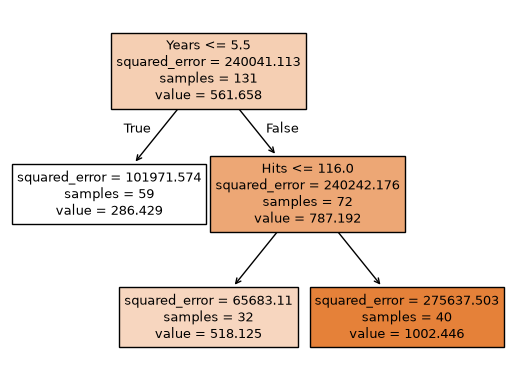

In [37]:
Tree3 = tree.DecisionTreeRegressor(max_leaf_nodes=3)
Tree3 = Tree3.fit(X_train, y_train)

tree.plot_tree(Tree3, 
               feature_names=Tree3.feature_names_in_.tolist(),
               filled=True)
plt.show()

#### 3.4 Jak dobry jest nasz model (zadanie regresji)?

Błąd średniokwadratowy:

$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{f}(x_i))^2$,

gdzie:

$y_i$ - wartość prawdziwa dla $i$-tej obserwacji,

$\hat{f}(x_i)$ jest predykcją modelu dla $i$-tej obserwacji.

In [61]:
# Generowanie prognoz (Prediction)
# Używamy wytrenowanych modeli do przewidywania wartości 'Salary' na nieznanych danych (X_test).

# Obliczanie Błędu Średniokwadratowego (Mean Squared Error - MSE)

print(mean_squared_error(y_test, Tree.predict(X_test)))
print(mean_squared_error(y_test, Tree3.predict(X_test)))
print(mean_squared_error(y_test, np.random.permutation(y_test)))

197787.25520397729
118732.01116872746
354734.3409107878


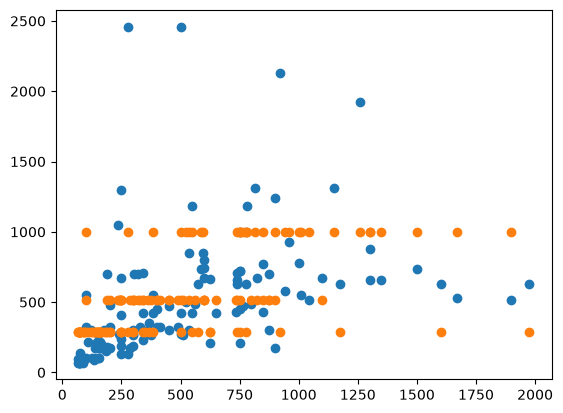

In [65]:
plt.scatter(y_test, Tree.predict(X_test))
plt.scatter(y_test, Tree3.predict(X_test))

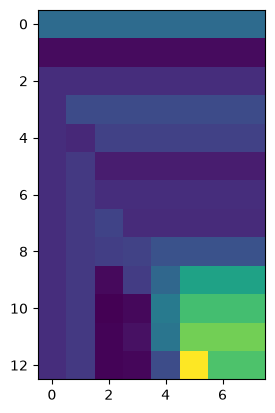

In [84]:
max_leaf_nodes = [*range(2, 15)]
max_depth = [*range(2, 10)]
mse = []

for i in max_leaf_nodes:
    m = []
    for j in max_depth:
        TreeH = tree.DecisionTreeRegressor(max_leaf_nodes=i, max_depth=j)
        TreeH = TreeH.fit(X_train, y_train)
        m.append(mean_squared_error(y_test, TreeH.predict(X_test)))
    mse.append(m)

plt.imshow(mse)